# Assignment 26 — Week 2, Day 1
## Topic: Python — Exception Handling

**Objective:** Complete the exercise on exception handling in Python.

**Reference:** https://www.programiz.com/python-programming/exception-handling

**Diagram:** An unhandled exception stops the program; a handled one lets it continue.

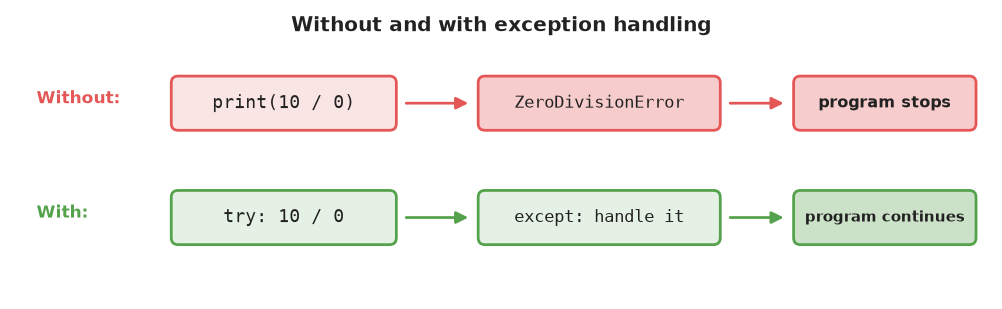

**What happens without exception handling**

In [1]:
numerator = 10
denominator = 0

try:
    result = numerator / denominator
except ZeroDivisionError as error:
    print("Without a try block, the program would stop here with:")
    print(type(error).__name__ + ":", error)

print("This line still runs.")

Without a try block, the program would stop here with:
ZeroDivisionError: division by zero
This line still runs.


**Explanation:** Dividing by zero raises a ZeroDivisionError. Without handling, Python would stop the program and show a traceback. The try...except block catches the error here so the rest of the notebook can still run.

**Diagram:** Some built-in exceptions and code that raises them.

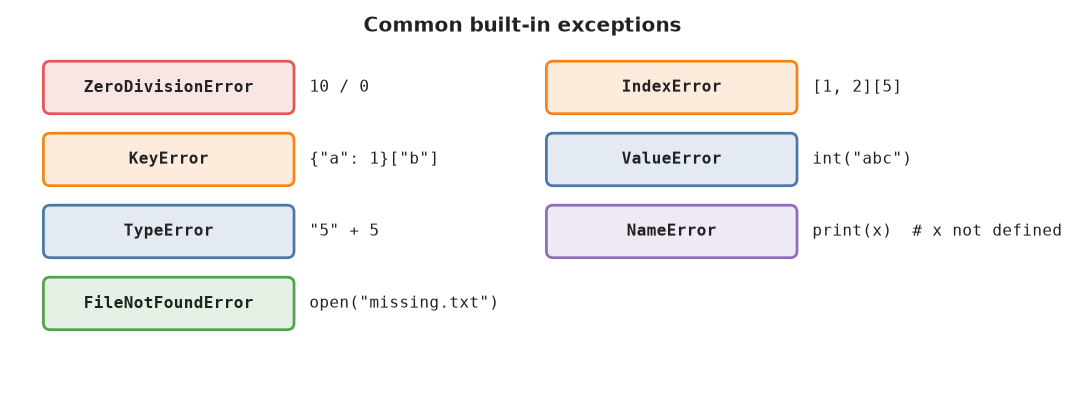

**Common built-in exceptions**

In [2]:
tests = [
    lambda: 10 / 0,
    lambda: [1, 2][5],
    lambda: {"a": 1}["b"],
    lambda: int("abc"),
    lambda: "5" + 5,
    lambda: open("missing_file.txt"),
]

for test in tests:
    try:
        test()
    except Exception as error:
        print(f"{type(error).__name__}: {error}")

ZeroDivisionError: division by zero
IndexError: list index out of range
KeyError: 'b'
ValueError: invalid literal for int() with base 10: 'abc'
TypeError: can only concatenate str (not "int") to str
FileNotFoundError: [Errno 2] No such file or directory: 'missing_file.txt'


**Explanation:** Each piece of code raises a different built-in exception. Catching Exception and printing the class name shows which error each one produces.

**try...except**

In [3]:
try:
    numerator = 10
    denominator = 0

    result = numerator / denominator
    print(result)
except:
    print("Error: Denominator cannot be 0.")

Error: Denominator cannot be 0.


**Explanation:** The code that might fail goes inside try. When an exception happens, the rest of the try block is skipped and the except block runs instead.

**Catch a specific exception**

In [4]:
try:
    even_numbers = [2, 4, 6, 8]
    print(even_numbers[5])
except ZeroDivisionError:
    print("Denominator cannot be 0.")
except IndexError:
    print("Index Out of Bound.")

Index Out of Bound.


**Explanation:** Each except block can name the exception it handles. Python runs the first matching block, so here IndexError is handled and ZeroDivisionError is skipped.

**Handle several exceptions in one block**

In [5]:
for value in ["25", "abc", 0]:
    try:
        number = int(value)
        print(100 / number)
    except (ValueError, ZeroDivisionError) as error:
        print(f"Could not use {value!r}: {type(error).__name__}")

4.0
Could not use 'abc': ValueError
Could not use 0: ZeroDivisionError


**Explanation:** Several exception types can be grouped in a tuple to share one except block. as error stores the exception object so its details can be used.

**Diagram:** Which blocks run depends on whether an exception is raised. finally always runs.

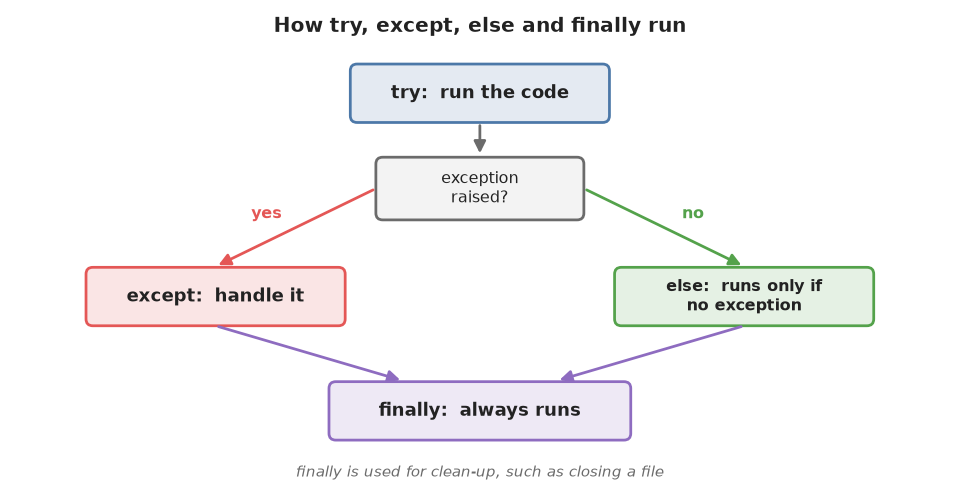

**try with else**

In [6]:
def reciprocal(num):
    try:
        assert num % 2 == 0
    except AssertionError:
        print("Not an even number!")
    else:
        print("Reciprocal:", 1 / num)

reciprocal(4)
reciprocal(5)

Reciprocal: 0.25
Not an even number!


**Explanation:** The else block runs only when the try block finishes without an exception. For 4 the check passes and else runs; for 5 the assertion fails, so except runs instead.

**try with finally**

In [7]:
try:
    numerator = 10
    denominator = 0

    result = numerator / denominator
    print(result)
except ZeroDivisionError:
    print("Error: Denominator cannot be 0.")
finally:
    print("This is finally block.")

Error: Denominator cannot be 0.
This is finally block.


**Explanation:** The finally block always runs, whether an exception happened or not. It is usually used for clean-up, such as closing files or connections.

**All four blocks together**

In [8]:
def safe_divide(a, b):
    try:
        result = a / b
    except ZeroDivisionError:
        print(f"{a} / {b}: cannot divide by zero")
    else:
        print(f"{a} / {b} = {result}")
    finally:
        print("Calculation finished\n")

safe_divide(10, 2)
safe_divide(10, 0)

10 / 2 = 5.0
Calculation finished

10 / 0: cannot divide by zero
Calculation finished



**Explanation:** With b = 2, try succeeds so else runs; with b = 0, except runs. finally runs in both cases.

**Validate user input**

In [9]:
inputs = ["42", "forty-two"]

for user_input in inputs:
    try:
        age = int(user_input)
        print("Age entered:", age)
    except ValueError:
        print(f"'{user_input}' is not a valid number. Please enter digits only.")

Age entered: 42
'forty-two' is not a valid number. Please enter digits only.


**Explanation:** A common use of exception handling is checking input. int() raises a ValueError for text that is not a number, and the except block shows a helpful message instead of crashing. A fixed list is used here so the notebook runs without asking for input.

**Raise an exception**

In [10]:
def withdraw(balance, amount):
    if amount > balance:
        raise ValueError("Insufficient balance")
    return balance - amount

print(withdraw(500, 200))

try:
    print(withdraw(500, 800))
except ValueError as error:
    print("Error:", error)

300
Error: Insufficient balance


**Explanation:** raise creates an exception on purpose when the code detects a problem. The caller can then catch it with try...except.

## Observation

- An exception is an error that happens while the program runs; if it is not handled, the program stops.
- Code that might fail goes in try, and except handles the error.
- An except block can name a specific exception, or a tuple of several.
- else runs only when no exception occurs, and finally always runs.
- as error gives access to the exception object and its message.
- raise creates an exception on purpose.

## Conclusion

Exception handling lets a program deal with errors such as division by zero, missing keys or bad input in a controlled way. Instead of crashing, the program can show a clear message, clean up and continue.